## Import Library

In [11]:
# NIM: 202431149
# Nama: Benedict Samuel Ardy
# Import Library yang dibutuhkan untuk analisis dan machine learning
import numpy as np           # untuk operasi array dan numerik
import pandas as pd          # untuk manipulasi dan membaca dataset
import matplotlib.pyplot as plt # untuk visualisasi grafik
import seaborn as sns        # untuk visualisasi statistik yang lebih menarik

# Mengatur agar plot muncul langsung di Jupyter Notebook
%matplotlib inline

## EDA

In [12]:
# NIM: 202431149
# Memuat dataset Heart Disease
df = pd.read_csv('01_heart_disease.csv', sep=",")

# Menampilkan 5 baris pertama data
print("=== 5 Data Pertama ===")
display(df.head())

# Mengetahui informasi struktur dataset (jumlah baris, kolom, tipe data, missing value)
print("\n=== Informasi Dataset ===")
df.info()

# Statistik deskriptif dari data numerik
print("\n=== Statistik Deskriptif ===")
display(df.describe())

=== 5 Data Pertama ===


,Age,Sex,ChestPainType,RestingBP,Cholesterol,FastingBS,RestingECG,MaxHR,ExerciseAngina,Oldpeak,ST_Slope,HeartDisease
0,40,M,ATA,140,289,0,Normal,172,N,0.0,Up,0
1,49,F,NAP,160,180,0,Normal,156,N,1.0,Flat,1
2,37,M,ATA,130,283,0,ST,98,N,0.0,Up,0
3,48,F,ASY,138,214,0,Normal,108,Y,1.5,Flat,1
4,54,M,NAP,150,195,0,Normal,122,N,0.0,Up,0



=== Informasi Dataset ===
<class 'pandas.DataFrame'>
RangeIndex: 918 entries, 0 to 917
Data columns (total 12 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Age             918 non-null    int64  
 1   Sex             918 non-null    str    
 2   ChestPainType   918 non-null    str    
 3   RestingBP       918 non-null    int64  
 4   Cholesterol     918 non-null    int64  
 5   FastingBS       918 non-null    int64  
 6   RestingECG      918 non-null    str    
 7   MaxHR           918 non-null    int64  
 8   ExerciseAngina  918 non-null    str    
 9   Oldpeak         918 non-null    float64
 10  ST_Slope        918 non-null    str    
 11  HeartDisease    918 non-null    int64  
dtypes: float64(1), int64(6), str(5)
memory usage: 86.2 KB

=== Statistik Deskriptif ===


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,HeartDisease
count,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000,918.000000
mean,53.510893,132.396514,198.799564,0.233115,136.809368,0.887364,0.553377
std,9.432617,18.514154,109.384145,0.423046,25.460334,1.066570,0.497414
min,28.000000,0.000000,0.000000,0.000000,60.000000,-2.600000,0.000000
25%,47.000000,120.000000,173.250000,0.000000,120.000000,0.000000,0.000000
50%,54.000000,130.000000,223.000000,0.000000,138.000000,0.600000,1.000000
75%,60.000000,140.000000,267.000000,0.000000,156.000000,1.500000,1.000000
max,77.000000,200.000000,603.000000,1.000000,202.000000,6.200000,1.000000


C:\Users\Ben S.A\AppData\Local\Temp\ipykernel_4252\447653770.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(x='HeartDisease', data=df, palette='Set2')


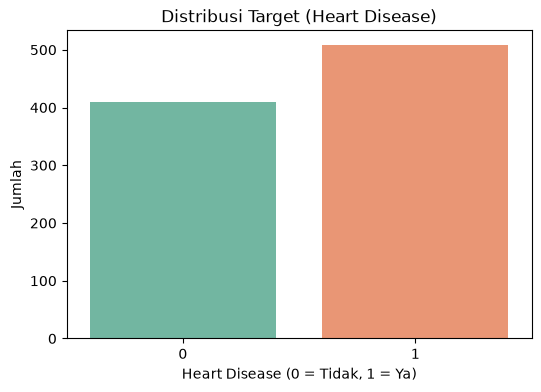

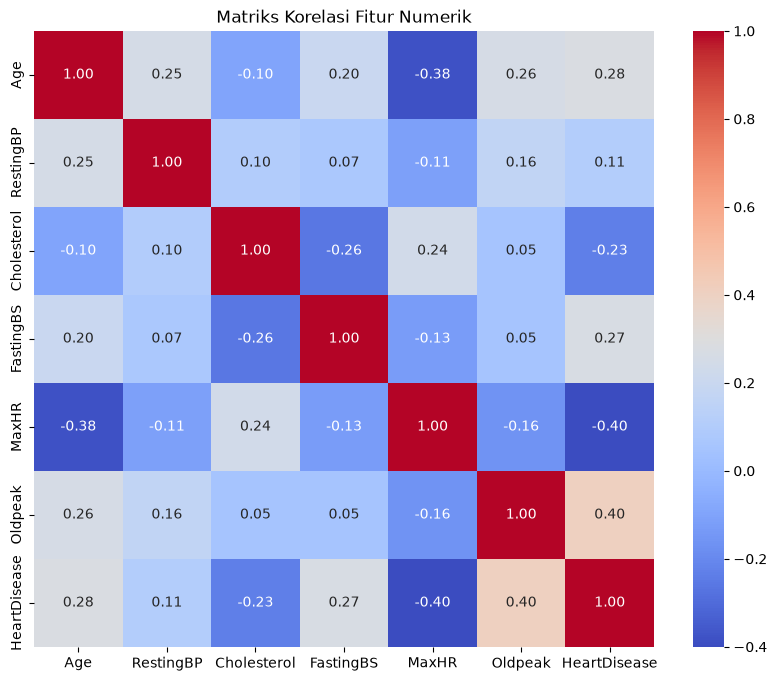

In [13]:
# NIM: 202431149
# Visualisasi distribusi target (HeartDisease)
plt.figure(figsize=(6, 4))
sns.countplot(x='HeartDisease', data=df, palette='Set2')
plt.title('Distribusi Target (Heart Disease)')
plt.xlabel('Heart Disease (0 = Tidak, 1 = Ya)')
plt.ylabel('Jumlah')
plt.show()

# Visualisasi Korelasi antar Fitur Numerik menggunakan Heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(df.select_dtypes(include=['int64', 'float64']).corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Matriks Korelasi Fitur Numerik')
plt.show()

## PreProcessing & Split Data

In [14]:
# NIM: 202431149
# Mengubah fitur kategorikal (string) menjadi numerik menggunakan One-Hot Encoding
df = pd.get_dummies(df, drop_first=True)

# Memisahkan Fitur (x) dan Target (y)
x = df.drop(['HeartDisease'], axis=1) # Variabel independen
y = df['HeartDisease']                 # Variabel dependen / target

print("=== Fitur Setelah Encoding ===")
display(x.head())

# Membagi data menjadi Data Latih (Train) 75% dan Data Uji (Test) 25%
from sklearn.model_selection import train_test_split
x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.25, random_state=42)

print(f'Ukuran x_train: {x_train.shape}')
print(f'Ukuran x_test : {x_test.shape}')

=== Fitur Setelah Encoding ===


,Age,RestingBP,Cholesterol,FastingBS,MaxHR,Oldpeak,Sex_M,ChestPainType_ATA,ChestPainType_NAP,ChestPainType_TA,RestingECG_Normal,RestingECG_ST,ExerciseAngina_Y,ST_Slope_Flat,ST_Slope_Up
0,40,140,289,0,172,0.0,True,True,False,False,True,False,False,False,True
1,49,160,180,0,156,1.0,False,False,True,False,True,False,False,True,False
2,37,130,283,0,98,0.0,True,True,False,False,False,True,False,False,True
3,48,138,214,0,108,1.5,False,False,False,False,True,False,True,True,False
4,54,150,195,0,122,0.0,True,False,True,False,True,False,False,False,True


Ukuran x_train: (688, 15)
Ukuran x_test : (230, 15)


## KNN

In [15]:
# NIM: 202431149
# Melakukan Standard Scaler agar rentang nilai fitur seragam (sangat penting untuk KNN)
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
scaler.fit(x_train)

x_train_scaled = scaler.transform(x_train)
x_test_scaled = scaler.transform(x_test)

### MODELING

=== EVALUASI MODEL KNN (K=7) ===
Akurasi KNN: 0.8870

Classification Report KNN:
               precision    recall  f1-score   support

           0       0.86      0.88      0.87        98
           1       0.91      0.89      0.90       132

    accuracy                           0.89       230
   macro avg       0.88      0.89      0.88       230
weighted avg       0.89      0.89      0.89       230



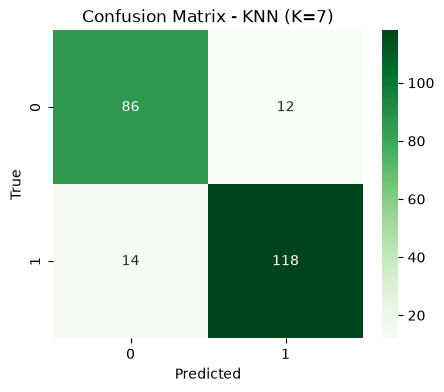

In [16]:
# NIM: 202431149
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# Inisialisasi dan training model KNN (Menggunakan K=7)
K_TARGET = 7 
knn = KNeighborsClassifier(n_neighbors=K_TARGET)
knn.fit(x_train_scaled, y_train)

# Prediksi dan Evaluasi KNN
y_pred_knn = knn.predict(x_test_scaled)
akurasi_knn = accuracy_score(y_test, y_pred_knn)

print(f"=== EVALUASI MODEL KNN (K={K_TARGET}) ===")
print(f"Akurasi KNN: {akurasi_knn:.4f}")
print("\nClassification Report KNN:\n", classification_report(y_test, y_pred_knn))

# Visualisasi Confusion Matrix KNN
plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_knn), annot=True, fmt='d', cmap='Greens')
plt.title(f'Confusion Matrix - KNN (K={K_TARGET})')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()

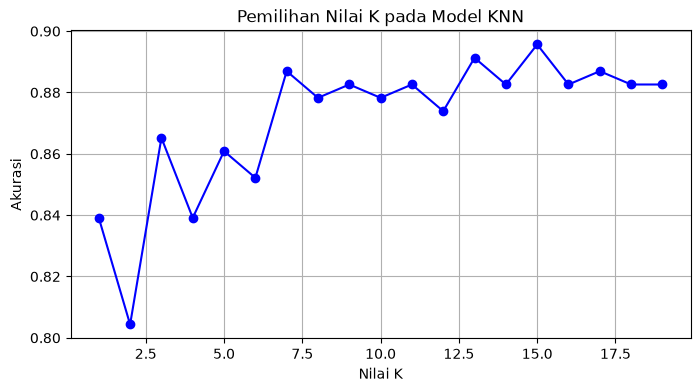

In [17]:
# NIM: 202431149
# Mencari nilai K optimal menggunakan looping
k_values = range(1, 20)
accuracies = []

for k in k_values:
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(x_train_scaled, y_train)
    y_pred_k = model.predict(x_test_scaled)
    accuracies.append(accuracy_score(y_test, y_pred_k))

# Plot Pemilihan Nilai K
plt.figure(figsize=(8, 4))
plt.plot(k_values, accuracies, marker='o', color='b')
plt.xlabel("Nilai K")
plt.ylabel("Akurasi")
plt.title("Pemilihan Nilai K pada Model KNN")
plt.grid(True)
plt.show()

## DECISION TREE

=== EVALUASI MODEL DECISION TREE ===
Akurasi Decision Tree: 0.8043

Classification Report Decision Tree:
               precision    recall  f1-score   support

           0       0.77      0.77      0.77        98
           1       0.83      0.83      0.83       132

    accuracy                           0.80       230
   macro avg       0.80      0.80      0.80       230
weighted avg       0.80      0.80      0.80       230

Kedalaman Pohon (Tree Depth): 13


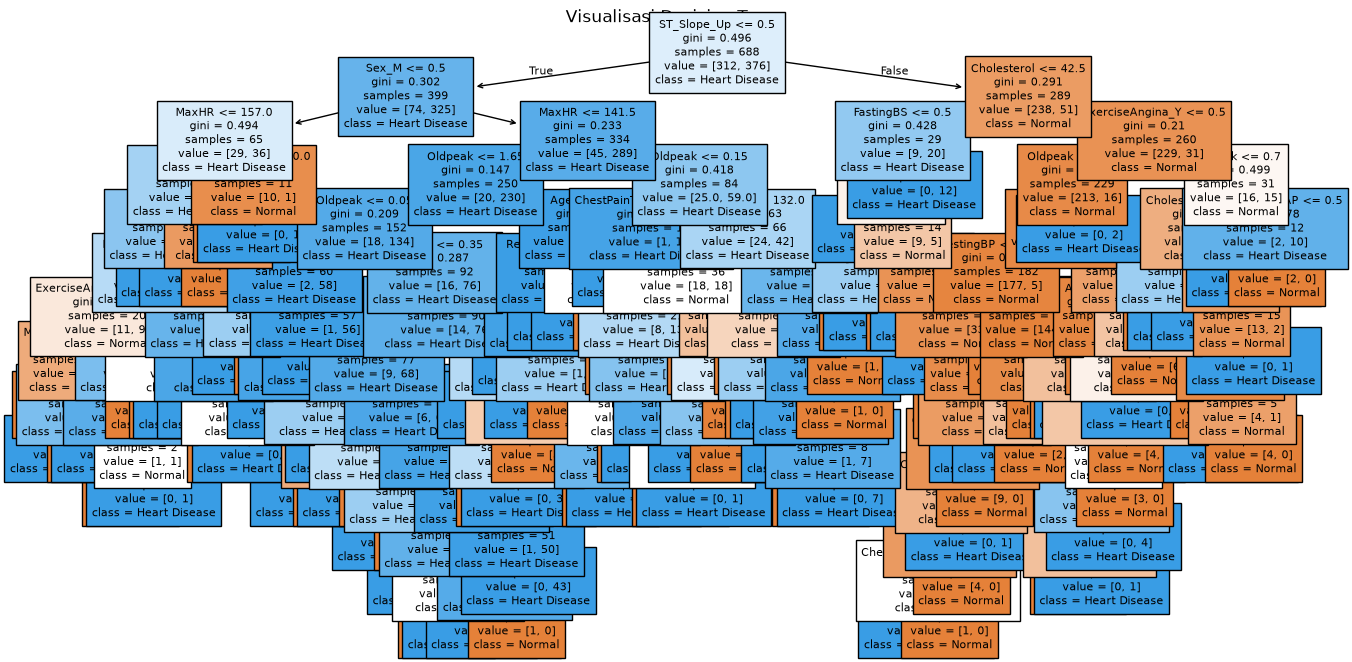

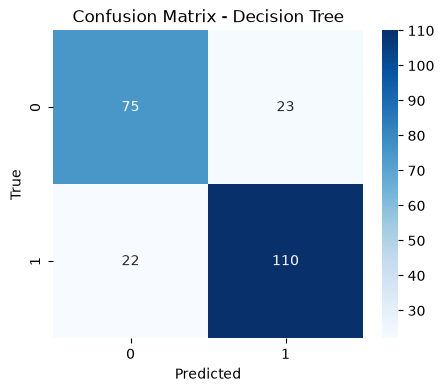

In [19]:
# NIM: 202431149
from sklearn.tree import DecisionTreeClassifier
from sklearn import tree

# Inisialisasi dan training model Decision Tree (menggunakan data asli tanpa scaling)
dt_classifier = DecisionTreeClassifier(random_state=42)
dt_classifier.fit(x_train, y_train)

# Prediksi dan Evaluasi Decision Tree
y_pred_dt = dt_classifier.predict(x_test)
akurasi_dt = accuracy_score(y_test, y_pred_dt)

print("=== EVALUASI MODEL DECISION TREE ===")
print(f"Akurasi Decision Tree: {akurasi_dt:.4f}")
print("\nClassification Report Decision Tree:\n", classification_report(y_test, y_pred_dt))
print(f"Kedalaman Pohon (Tree Depth): {dt_classifier.get_depth()}")

# Visualisasi Pohon Keputusan (Decision Tree)
plt.figure(figsize=(16, 8))
tree.plot_tree(dt_classifier, filled=True, feature_names=x.columns, class_names=['Normal', 'Heart Disease'], fontsize=8)
plt.title("Visualisasi Decision Tree")
plt.show()

# Visualisasi Confusion Matrix Decision Tree
plt.figure(figsize=(5, 4))
sns.heatmap(confusion_matrix(y_test, y_pred_dt), annot=True, fmt='d', cmap='Blues')
plt.title('Confusion Matrix - Decision Tree')
plt.xlabel('Predicted')
plt.ylabel('True')
plt.show()